# Lab 2: K-Means Clustering and the Elbow Method

MLPR, Semester 4. Generates four Gaussian clusters, computes the within-cluster sum of squares (WCSS) for K = 1 to 20, chooses K with the elbow method and clusters the data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

np.random.seed(0)
params = [([2, 2], [[0.9, -0.0255], [-0.0255, 0.9]]),
          ([5, 5], [[0.5, 0], [0, 0.3]]),
          ([-2, -2], [[1, 0], [0, 0.9]]),
          ([-4, 8], [[0.8, 0], [0, 0.6]])]
data = np.vstack([np.random.multivariate_normal(mu, sigma, 100) for mu, sigma in params])

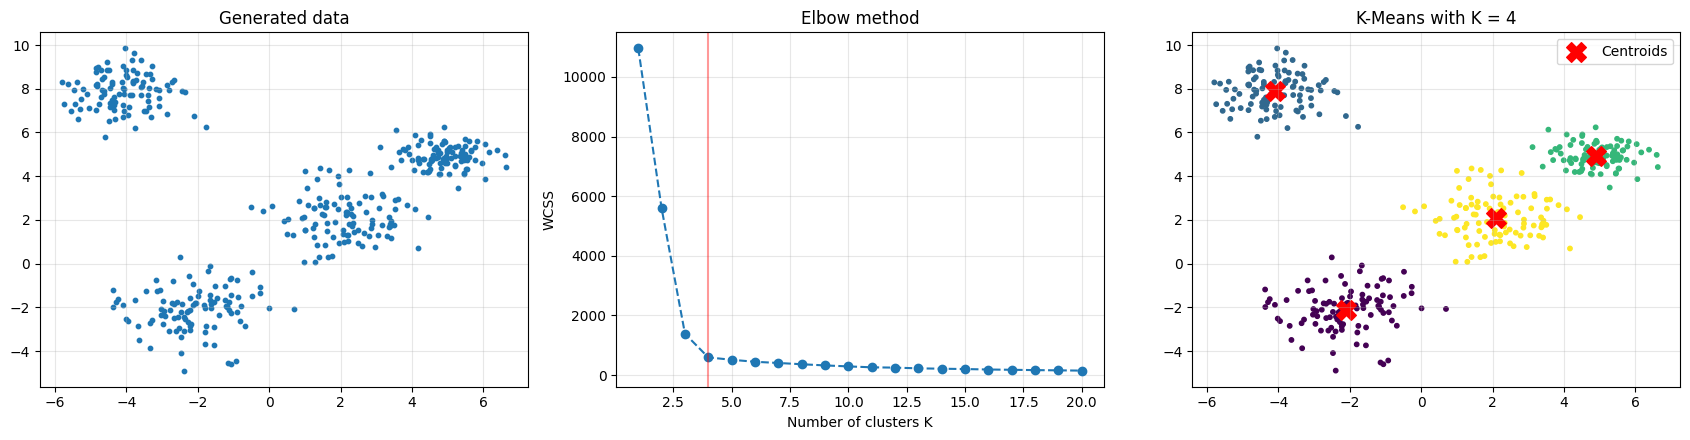

WCSS for K = 1..6: [10955.8  5587.7  1384.1   591.5   512.    444.9]


In [2]:
wcss = [KMeans(n_clusters=k, random_state=0, n_init=10).fit(data).inertia_ for k in range(1, 21)]
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10).fit(data)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(data[:, 0], data[:, 1], s=10)
axes[0].set_title("Generated data")
axes[1].plot(range(1, 21), wcss, marker="o", linestyle="--")
axes[1].axvline(4, color="r", alpha=0.4)
axes[1].set_title("Elbow method"); axes[1].set_xlabel("Number of clusters K"); axes[1].set_ylabel("WCSS")
axes[2].scatter(data[:, 0], data[:, 1], c=kmeans.labels_, s=10)
axes[2].scatter(*kmeans.cluster_centers_.T, s=200, c="red", marker="X", label="Centroids")
axes[2].set_title("K-Means with K = 4"); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("images/lab02_kmeans.png")
plt.show()
print("WCSS for K = 1..6:", np.round(wcss[:6], 1))

The WCSS drops steeply up to K = 4 and flattens afterwards, so the elbow correctly finds the four generated clusters.

## Report

1. If K is too low, distinct groups are merged into one large, mixed cluster. If K is too high, real clusters are split into redundant pieces, and in the extreme every point becomes its own cluster.
2. The initial centroids affect the result. Badly placed starting centroids can converge to a poor local optimum, or put two centroids inside the same true cluster.
3. K-Means can be improved with smarter initialisation such as K-Means++ (spread-out starting centroids) and by running several initialisations (`n_init`) and keeping the best.
4. The elbow method fails when the WCSS curve has no sharp bend, or has several bends, so the choice of K becomes subjective.
5. Outliers and noise increase the WCSS, pull centroids away from the true cluster centres and can hide the elbow.